# مشروع تحليل بيانات FIFA 2019 باستخدام Python

## Project Overview

يهدف هذا المشروع إلى بناء سير عمل منظم واحترافي لتحليل بيانات لاعبي FIFA 2019، بدءًا من تحميل البيانات وفحص جودتها، مرورًا بتنظيفها وتجهيزها، ثم إجراء **التحليل الاستكشافي للبيانات (EDA)** والتصور البصري، وانتهاءً ببناء نماذج انحدار بسيطة لاستكشاف العلاقة بين **التقييم العام للاعب (Overall)** و**قيمة اللاعب (Value)**.

### أهداف المشروع
1. فهم بنية البيانات وجودتها قبل إجراء أي تحليل.
2. اكتشاف القيم المفقودة والتعامل معها بطريقة قابلة للتفسير.
3. توحيد بعض القيم النصية وتجهيز المتغيرات الرقمية.
4. استخراج إحصاءات وصفية وعلاقات بين المتغيرات.
5. بناء رسوم بيانية تساعد على فهم البيانات.
6. اختبار العلاقة بين Overall وValue باستخدام الارتباط والانحدار.
7. توثيق كل خطوة بطريقة تعليمية ومنظمة.

> **ملاحظة:** الملف المستخدم هو نسخة تعليمية من بيانات FIFA 2019، ولذلك قد تختلف النتائج عن النسخة الكاملة المنشورة من مجموعة البيانات الأصلية.

## خريطة المشروع

سنقسم العمل إلى المراحل التالية:

1. **استيراد المكتبات وتحميل البيانات**
2. **الفحص الأولي للبيانات**
3. **تنظيف البيانات والتعامل مع القيم المفقودة**
4. **تنسيق البيانات وFeature Engineering**
5. **التحليل الاستكشافي والتصور البصري**
6. **تحليل الارتباط**
7. **نمذجة الانحدار**
8. **تقييم النماذج**
9. **الخلاصة والاستنتاجات**

# 1. استيراد المكتبات وتحميل البيانات

## لماذا هذه الخطوة؟

نبدأ باستيراد المكتبات التي سنحتاج إليها في التحليل. استخدام مجموعة واضحة من المكتبات في خلية واحدة يجعل النوت بوك أسهل في القراءة وإعادة التشغيل.

سنستخدم:
- **Pandas** لإدارة البيانات.
- **NumPy** للعمليات العددية.
- **Matplotlib / Seaborn** للتصور البصري.
- **SciPy** لاختبار الارتباط.
- **Scikit-learn** لبناء نماذج الانحدار وتقييمها.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# إعدادات عامة للرسوم
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## تحميل ملف البيانات

سنستخدم `Path` لاختيار الملف سواء كان المشروع يعمل في **Google Colab** أو على جهاز محلي.

**النتيجة المتوقعة:** إنشاء DataFrame باسم `df` يحتوي على بيانات اللاعبين.

In [ ]:
df = pd.read_excel("Fifa2019Data.xlsx")

print(df.shape)

(158, 44)


# 2. الاستكشاف الأولي للبيانات (Initial EDA)

## لماذا نفحص البيانات قبل تنظيفها؟

من الخطأ البدء مباشرةً في حذف القيم أو تعديل الأعمدة قبل فهم بنية البيانات. لذلك سنفحص:
- أول وآخر الصفوف.
- أنواع البيانات.
- عدد الصفوف والأعمدة.
- القيم المفقودة.
- الإحصاءات الوصفية.

هذه الخطوة تعطينا **خط أساس (Baseline)** قبل أي تعديل.

In [ ]:
# عرض عينة من بداية البيانات
display(df.head())

# عرض عينة من نهاية البيانات
display(df.tail())

,Name,Age,Nationality,Overall,Potential,Club,Preferred Foot,Position,Jersey Number,Crossing,Finishing,HeadingAccuracy,ShortPassing,Volleys,Dribbling,Curve,FKAccuracy,LongPassing,BallControl,Acceleration,SprintSpeed,Agility,Reactions,Balance,ShotPower,Jumping,Stamina,Strength,LongShots,Aggression,Interceptions,Positioning,Vision,Penalties,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Value
0,L. Messi,31.00,Argentina,94.00,94.00,FC Barcelona,Left,RF,10,84.00,95,70,90,86,97,93,94,87,96,91,86,91,95,95,85,68,72,59,94,48,22,94,94,75,96,33,28,26,6,11,15,14,8,110500000
1,Cristiano Ronaldo,33.00,Portugal,94.00,94.00,Juventus,Right,ST,7,79.00,94,89,81,87,88,81,76,77,94,89,91,87,96,70,95,95,88,79,93,63,29,95,82,85,95,28,31,23,7,11,15,14,11,77000000
2,Neymar Jr,26.00,Brazil,92.00,93.00,Paris Saint-Germain,Right,LW,10,NaN,87,62,84,84,96,88,87,78,95,94,90,96,94,84,80,61,81,49,82,56,36,89,87,81,94,27,24,33,9,9,15,15,11,118500000
3,De Gea,27.00,Spain,91.00,93.00,Manchester United,Right,GK,1,17.00,13,21,50,13,18,21,19,51,42,57,58,60,90,43,31,67,43,64,12,38,30,12,68,40,68,15,21,13,90,85,87,88,94,72000000
4,K. De Bruyne,27.00,Belgium,91.00,92.00,Manchester City,Right,RCM,7,93.00,82,55,92,82,86,85,83,91,91,78,76,79,91,77,91,63,90,75,91,76,61,87,94,79,88,68,58,51,15,13,5,10,13,102000000


,Name,Age,Nationality,Overall,Potential,Club,Preferred Foot,Position,Jersey Number,Crossing,Finishing,HeadingAccuracy,ShortPassing,Volleys,Dribbling,Curve,FKAccuracy,LongPassing,BallControl,Acceleration,SprintSpeed,Agility,Reactions,Balance,ShotPower,Jumping,Stamina,Strength,LongShots,Aggression,Interceptions,Positioning,Vision,Penalties,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Value
153,Rodrigo,27.00,Spain,83.00,84.00,Valencia CF,Left,ST,9,72.00,78,80,78,77,82,83,67,58,82,88,91,84,80,77,83,78,78,72,76,60,31,83,74,77,77,44,41,40,7,13,10,11,5,30500000
154,Pizzi,28.00,Portugal,83.00,83.00,SL Benfica,Right,LCM,21,79.00,76,45,83,77,80,83,76,84,82,82,73,77,81,77,75,67,86,59,78,68,70,84,85,76,85,66,66,52,15,14,9,9,15,25500000
155,K. Kampl,27.00,Slovenia,83.00,83.00,RB Leipzig,Right,LCM,44,72.00,63,34,84,68,86,78,75,79,84,84,71,91,84,80,69,67,88,47,73,64,75,73,82,64,83,65,64,59,13,11,7,6,16,26500000
156,Neto,28.00,Brazil,83.00,84.00,Valencia CF,Right,GK,13,11.00,15,14,36,12,19,12,13,41,24,53,49,59,79,49,28,80,39,63,20,40,15,11,42,22,64,17,14,15,85,79,79,78,82,21000000
157,O. Baumann,28.00,Germany,83.00,84.00,TSG 1899 Hoffenheim,Right,GK,1,14.00,11,16,30,11,19,12,11,25,17,47,51,45,81,43,21,73,39,69,13,32,21,10,41,22,52,15,18,14,82,82,70,82,85,21000000


In [ ]:
# معلومات عامة عن DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 44 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             158 non-null    object 
 1   Age              157 non-null    float64
 2   Nationality      157 non-null    object 
 3   Overall          157 non-null    float64
 4   Potential        157 non-null    float64
 5   Club             158 non-null    object 
 6   Preferred Foot   158 non-null    object 
 7   Position         158 non-null    object 
 8   Jersey Number    158 non-null    int64  
 9   Crossing         157 non-null    float64
 10  Finishing        158 non-null    int64  
 11  HeadingAccuracy  158 non-null    int64  
 12  ShortPassing     158 non-null    int64  
 13  Volleys          158 non-null    int64  
 14  Dribbling        158 non-null    int64  
 15  Curve            158 non-null    int64  
 16  FKAccuracy       158 non-null    int64  
 17  LongPassing     

In [ ]:
# الإحصاءات الوصفية للمتغيرات الرقمية
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,157.00,27.31,3.50,21.00,25.00,27.00,30.00,40.00
Overall,157.00,85.40,2.42,83.00,84.00,85.00,87.00,94.00
Potential,157.00,87.18,2.69,83.00,85.00,87.00,89.00,94.00
Jersey Number,158.00,12.07,7.92,1.00,7.00,10.00,17.00,44.00
Crossing,157.00,63.34,23.01,9.00,52.00,72.00,80.00,93.00
Finishing,158.00,61.08,25.40,9.00,44.25,71.00,80.75,95.00
HeadingAccuracy,158.00,62.37,22.74,10.00,51.00,70.00,80.00,94.00
ShortPassing,158.00,75.82,14.90,30.00,75.00,81.00,84.00,93.00
Volleys,158.00,59.95,23.94,10.00,45.00,68.50,78.00,90.00
Dribbling,158.00,71.25,23.02,10.00,64.00,80.00,86.75,97.00


In [ ]:
# الإحصاءات الوصفية للمتغيرات النصية
display(df.describe(include="object").T)

,count,unique,top,freq
Name,158,158,L. Messi,1
Nationality,157,29,Brazil,29
Club,158,48,Manchester City,13
Preferred Foot,158,2,Right,117
Position,158,23,GK,20


In [ ]:
# عدد القيم المفقودة في كل عمود
missing = df.isna().sum()

result = missing[missing > 0].sort_values(ascending=False)

print(result)

Age            1
Nationality    1
Overall        1
Potential      1
Crossing       1
dtype: int64


## فحص التكرارات

التكرار ليس بالضرورة خطأ؛ فقد يكون أكثر من لاعب موجودًا بشكل صحيح. لذلك سنقيس التكرار على مستوى الصف الكامل، ثم نتحقق من تكرار أسماء اللاعبين بشكل منفصل.

**النتيجة المتوقعة:** معرفة ما إذا كانت هناك سجلات متطابقة تمامًا تحتاج إلى مراجعة.

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Names:", df["Name"].duplicated().sum())

Duplicate Rows: 0
Duplicate Names: 0


# 3. تنظيف البيانات (Data Cleaning)

## لماذا لا نستخدم `dropna()` على كامل البيانات؟

حذف كل صف يحتوي على قيمة مفقودة قد يؤدي إلى فقدان بيانات صحيحة في أعمدة أخرى. لذلك سنحدد أولًا أماكن النقص، ثم نستخدم طريقة مناسبة لكل نوع من الأعمدة.

في هذه البيانات توجد قيم مفقودة في بعض المتغيرات الرقمية مثل `Age` و`Overall` و`Potential` و`Crossing`. سنستخدم **الوسيط Median** للمتغيرات الرقمية، لأنه أقل تأثرًا بالقيم المتطرفة من المتوسط الحسابي.

أما الأعمدة النصية، فسنعالجها باستخدام القيمة الأكثر تكرارًا عند الحاجة.

In [ ]:
# نعمل نسخة مستقلة من البيانات الأصلية عشان نحافظ على df كما هو
df_clean = df.copy()

# تحديد الأعمدة الرقمية (Numbers)
numeric_cols = df_clean.select_dtypes(include=np.number).columns

# تحديد الأعمدة النصية / التصنيفية (Categorical)
categorical_cols = df_clean.select_dtypes(include="object").columns

# تعويض القيم المفقودة في الأعمدة الرقمية بالـ Median
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# تعويض القيم المفقودة في الأعمدة النصية بأكثر قيمة تكرارًا (Mode)
for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# التأكد من إجمالي عدد القيم المفقودة بعد عملية التنظيف
print("Missing Values:", df_clean.isna().sum().sum())

Missing Values: 0


## فحص القيم غير المنطقية

بالإضافة إلى `NaN`، يجب التأكد من أن القيم الرقمية تقع ضمن نطاقات منطقية.

سنفحص بشكل خاص:
- `Age`
- `Overall`
- `Potential`
- `Value`
- مهارات اللاعبين التي يفترض أن تكون بين 0 و100 تقريبًا.

**الهدف:** اكتشاف أخطاء الإدخال قبل الاعتماد على النتائج.

In [ ]:
# نطاقات المتغيرات الأساسية
range_check = pd.DataFrame({
    "Min": df_clean[["Age", "Overall", "Potential", "Value"]].min(),
    "Max": df_clean[["Age", "Overall", "Potential", "Value"]].max()
})

display(range_check)

# البحث عن قيم مهارات خارج النطاق المتوقع 0-100
skill_cols = [
    "Crossing", "Finishing", "HeadingAccuracy", "ShortPassing",
    "Volleys", "Dribbling", "Curve", "FKAccuracy", "LongPassing",
    "BallControl", "Acceleration", "SprintSpeed", "Agility",
    "Reactions", "Balance", "ShotPower", "Jumping", "Stamina",
    "Strength", "LongShots", "Aggression", "Interceptions",
    "Positioning", "Vision", "Penalties", "Composure", "Marking",
    "StandingTackle", "SlidingTackle", "GKDiving", "GKHandling",
    "GKKicking", "GKPositioning", "GKReflexes"
]

# البحث عن القيم خارج النطاق المتوقع 0-100
invalid = (df_clean[skill_cols] < 0) | (df_clean[skill_cols] > 100)

# حساب عدد القيم غير الصحيحة في كل عمود
invalid_counts = invalid.sum()

# ترتيب النتائج من الأكبر للأصغر وعرض المشاكل فقط
print(invalid_counts[invalid_counts > 0].sort_values(ascending=False))

,Min,Max
Age,21.00,40.00
Overall,83.00,94.00
Potential,83.00,94.00
Value,"4,000,000.00","118,500,000.00"


Series([], dtype: int64)


## توحيد أسماء بعض الأندية

قد تظهر بعض الأندية بصيغ مختلفة لنفس النادي، مثل:
- `R.Madrid`
- `Real M.`
- `R.M`

سنقوم بتوحيدها إلى `Real Madrid` حتى لا يتم تقسيم النادي إلى عدة مجموعات أثناء التحليل.

**ملاحظة:** هذه العملية مثال على **Data Standardization** وليست حذفًا للبيانات.

In [ ]:
# توحيد أسماء الأندية التي لها أكثر من صيغة
club_mapping = {

    "R.Madrid": "Real Madrid",
    "Real M.": "Real Madrid",
    "R.M": "Real Madrid",

}

# استبدال الأسماء القديمة بالاسم الموحد
df_clean["Club"] = df_clean["Club"].replace(club_mapping)

# عرض عدد الأندية المختلفة بعد توحيد الأسماء
print("Number of unique clubs after standardization:", df_clean["Club"].nunique())

Number of unique clubs after standardization: 45


## 4. Data Formatting & Feature Engineering

### Converting Player Value to Millions

The original player value is stored in the base currency unit.  
To make the data easier to read and analyze, we will create a new column called `Value_M` that represents the player's value in millions.

**Why create a new column?**

Keeping the original `Value` column allows us to preserve the raw data for validation and comparison, while `Value_M` provides a more convenient format for analysis and visualization.

In [ ]:
# تحويل قيمة اللاعب من العملة الأساسية إلى ملايين
df_clean["Value_M"] = df_clean["Value"] / 1_000_000

display(
    df_clean[["Name", "Overall", "Value", "Value_M"]].head()
)

,Name,Overall,Value,Value_M
0,L. Messi,94.00,110500000,110.50
1,Cristiano Ronaldo,94.00,77000000,77.00
2,Neymar Jr,92.00,118500000,118.50
3,De Gea,91.00,72000000,72.00
4,K. De Bruyne,91.00,102000000,102.00


## إنشاء فئات للتقييم العام

سنقسم `Overall` إلى ثلاث فئات تقريبية:
- Low
- Medium
- High

هذا مفيد عند إجراء تحليلات فئوية، لكنه **لا يستبدل القيمة الرقمية الأصلية**؛ سنحتفظ بالعمود `Overall` كما هو.

In [ ]:
# تحديد حدود التصنيف لقيمة Overall
overall_bins = [0, 80, 90, 100]

# تحديد اسم كل مستوى
overall_labels = ["Low", "Medium", "High"]

# تقسيم Overall إلى مستويات حسب الحدود المحددة
df_clean["Overall_Level"] = pd.cut(

    df_clean["Overall"],
 # ـ bins = الحدود اللي هنقسم الأرقام بناءً عليها.
    bins=overall_bins,
  #دي الأسماء اللي هتتحط بدل ـ Ranges.
    labels=overall_labels,
  #ضمّن أقل قيمة في أول Range.
    include_lowest=True,
  #دي بتحدد إن الحد اليمين داخل في الـ Range.
    right=True
)

# عرض أول 5 صفوف للتأكد من النتيجة
display(df_clean[["Overall", "Overall_Level"]].head())

,Overall,Overall_Level
0,94.00,High
1,94.00,High
2,92.00,High
3,91.00,High
4,91.00,High


## Min-Max Normalization

التطبيع ليس مطلوبًا لجميع التحليلات. سننشئ نسخة Min-Max من `Value_M` في عمود مستقل فقط لأغراض تعليمية.

الصيغة:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**مهم:** لن نستخدم القيمة الطبيعية بدل القيمة الأصلية في الرسوم التي نريد فيها تفسير القيمة بالملايين.

الـ Min-Max Normalization بتحوّل القيم إلى نطاق موحّد غالبًا من 0 إلى 1، مع الحفاظ على ترتيب القيم الأصلية.
مفيدة لما تكون القيم في نطاقات مختلفة ونحتاج نخليها أسهل للمقارنة أو لاستخدامها في Machine Learning.

In [ ]:
# حساب أقل قيمة للاعبين في العمود Value_M
value_min = df_clean["Value_M"].min()

# حساب أعلى قيمة للاعبين في العمود Value_M
value_max = df_clean["Value_M"].max()

# تطبيق Min-Max Scaling على قيم اللاعبين وتحويلها إلى نطاق من 0 إلى 1
df_clean["Value_M_MinMax"] = (
    (df_clean["Value_M"] - value_min)
    / (value_max - value_min)
)

# عرض القيم الأصلية والقيم بعد تطبيق Min-Max Scaling
display(df_clean[["Value_M", "Value_M_MinMax"]].head())

,Value_M,Value_M_MinMax
0,110.50,0.93
1,77.00,0.64
2,118.50,1.00
3,72.00,0.59
4,102.00,0.86


# 5. التحليل الاستكشافي والتصور البصري (EDA & Visualization)

سنبدأ الآن بتحليل الأسئلة التي يمكن الإجابة عنها مباشرة من البيانات:
- كيف يتوزع عمر اللاعبين؟
- كيف تتوزع قيم اللاعبين؟
- هل توجد علاقة بين Overall وValue؟
- ما الأندية التي تمتلك أعلى متوسط قيمة؟
- كيف تختلف القيم حسب مستوى Overall؟

الرسوم هنا ليست للزينة؛ الهدف منها تحويل الأرقام إلى أنماط يمكن تفسيرها.

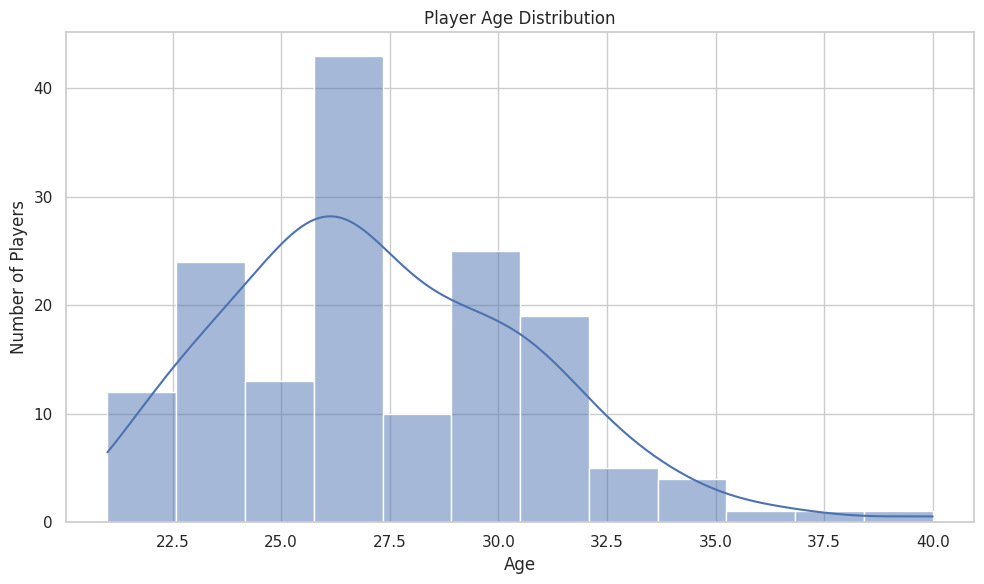

In [ ]:
# توزيع أعمار اللاعبين
plt.figure(figsize=(10, 6))

sns.histplot(data=df_clean, x="Age", bins=12, kde=True)

plt.title("Player Age Distribution")

plt.xlabel("Age")

plt.ylabel("Number of Players")

plt.tight_layout()

plt.show()

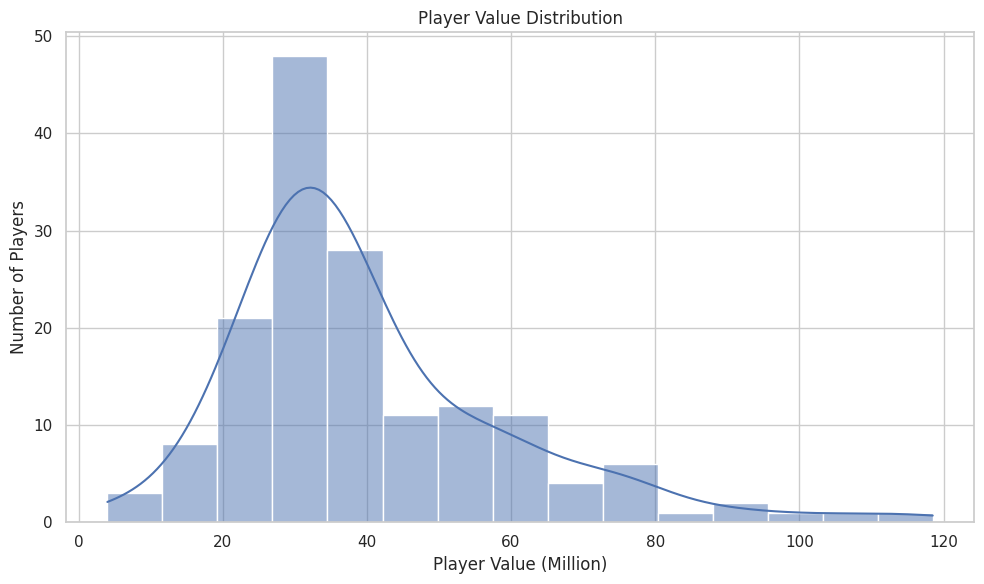

In [ ]:
# توزيع قيمة اللاعبين
plt.figure(figsize=(10, 6))

sns.histplot(data=df_clean, x="Value_M", bins=15, kde=True)

plt.title("Player Value Distribution")

plt.xlabel("Player Value (Million)")

plt.ylabel("Number of Players")

plt.tight_layout()

plt.show()

## العلاقة بين Overall وValue

سنستخدم Scatter Plot لمراقبة العلاقة بين التقييم العام وقيمة اللاعب.

**النتيجة المتوقعة:** إذا كان هناك ارتباط موجب، فسنلاحظ ميلًا عامًا لارتفاع القيمة مع ارتفاع Overall، مع احتمال وجود تشتت واضح لأن قيمة اللاعب لا تعتمد على Overall وحده.

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="Overall",
    y="Value_M",
    hue="Overall_Level",
    palette="viridis",
    s=80
)
plt.title("العلاقة بين التقييم العام وقيمة اللاعب")
plt.xlabel("Overall")
plt.ylabel("قيمة اللاعب (مليون)")
plt.legend(title="مستوى Overall")
plt.tight_layout()
plt.show()

## أعلى الأندية من حيث متوسط قيمة اللاعبين

سنحسب متوسط `Value_M` لكل نادٍ، ثم نعرض أعلى 10 أندية من حيث المتوسط.

**تنبيه منهجي:** هذا التحليل يقارن متوسطات العينة الموجودة في الملف فقط، وليس القيمة السوقية الحقيقية لكل نادٍ على مستوى العالم.

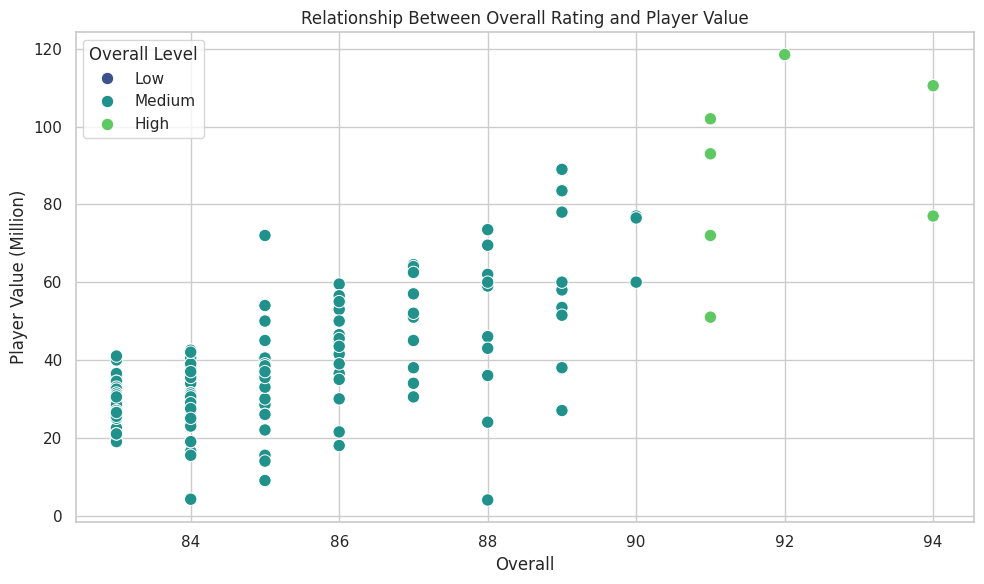

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Overall",
    y="Value_M",
    hue="Overall_Level",
    palette="viridis",
    s=80
)
#s = حجم كل نقطة على الرسم
plt.title("Relationship Between Overall Rating and Player Value")

plt.xlabel("Overall")

plt.ylabel("Player Value (Million)")

plt.legend(title="Overall Level")

plt.tight_layout()

plt.show()

## متوسط Overall حسب الجنسية

سنحسب متوسط التقييم العام لكل جنسية، مع عرض الجنسيات التي لديها عدد كافٍ من اللاعبين في العينة لتقليل تأثير المجموعات الصغيرة.

سنستخدم حدًا أدنى قدره **3 لاعبين** في هذا الجزء.

In [ ]:
nationality_summary = (
    df_clean.groupby("Nationality")
    .agg(
        Players=("Name", "count"),
        Mean_Overall=("Overall", "mean"),
        Mean_Value_M=("Value_M", "mean")
    )
    .query("Players >= 3")
    .sort_values("Mean_Overall", ascending=False)
)

display(nationality_summary.head(10))

,Players,Mean_Overall,Mean_Value_M
Nationality,,,
Argentina,6,87.17,58.50
Belgium,11,86.82,49.41
Italy,10,85.90,32.07
Spain,23,85.57,39.98
Portugal,7,85.43,40.86
Germany,15,85.27,38.57
Brazil,30,84.97,37.17
England,6,84.83,43.42
France,20,84.75,40.60


## Boxplot لقيمة اللاعبين حسب مستوى Overall

يساعد Boxplot على مقارنة الوسيط والتشتت والقيم المتطرفة بين الفئات.

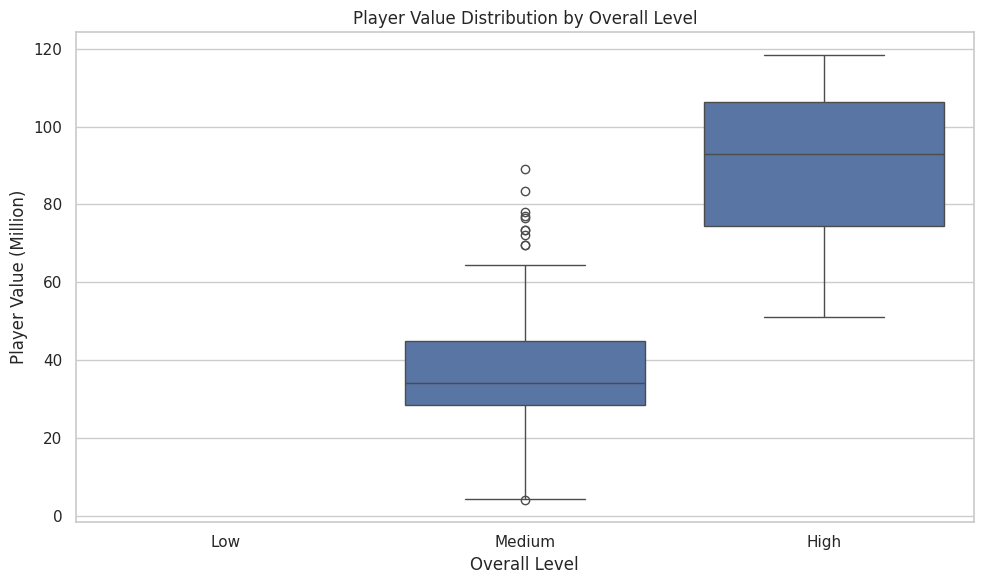

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_clean, x="Overall_Level", y="Value_M")

plt.title("Player Value Distribution by Overall Level")

plt.xlabel("Overall Level")

plt.ylabel("Player Value (Million)")

plt.tight_layout()

plt.show()

# 6. تحليل الارتباط (Correlation)

سنحسب معامل Pearson بين بعض المتغيرات الرقمية.

**التفسير:**
- قيمة قريبة من `+1`: علاقة خطية موجبة قوية.
- قيمة قريبة من `-1`: علاقة خطية سالبة قوية.
- قيمة قريبة من `0`: لا توجد علاقة خطية واضحة.

الارتباط لا يعني السببية.

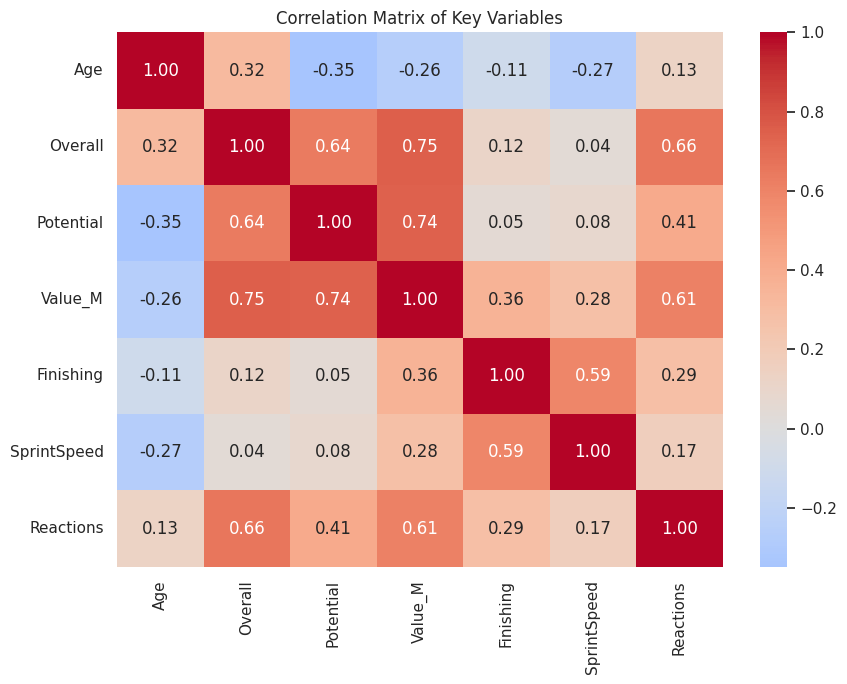

In [ ]:
# تحديد الأعمدة التي نريد حساب الارتباط بينها
corr_cols = [
    "Age", "Overall", "Potential", "Value_M",
    "Finishing", "SprintSpeed", "Reactions"
]

# حساب معامل الارتباط بين كل زوج من المتغيرات
corr_matrix = df_clean[corr_cols].corr()

# تحديد حجم الشكل الذي سيظهر فيه الرسم
plt.figure(figsize=(9, 7))

# رسم مصفوفة الارتباط على شكل Heatmap
sns.heatmap(
    corr_matrix,

    # إظهار قيمة الارتباط داخل كل خلية
    annot=True,

    # عرض قيم الارتباط بمنزلتين عشريتين
    fmt=".2f",

    # تحديد ألوان الـ Heatmap
    cmap="coolwarm",

    # جعل القيمة صفر هي نقطة المنتصف في مقياس الألوان
    center=0
)

# وضع عنوان للرسم
plt.title("Correlation Matrix of Key Variables")

# ضبط المسافات داخل الشكل حتى لا تتداخل العناصر
plt.tight_layout()

# عرض الرسم
plt.show()

## اختبار Pearson بين Overall وValue

لنحسب معامل الارتباط وقيمة `p-value`.

**مهم:** قيمة `p-value` تساعدنا في اختبار وجود علاقة خطية إحصائيًا، لكنها لا تخبرنا بحجم الأثر ولا تثبت السببية.

In [ ]:
# حساب معامل Pearson للارتباط بين Overall و Value_M
# corr_overall_value = قوة واتجاه العلاقة
# p_overall_value = القيمة الاحتمالية لاختبار دلالة العلاقة
corr_overall_value, p_overall_value = pearsonr(

    # المتغير الأول: التقييم العام للاعب
    df_clean["Overall"],

    # المتغير الثاني: قيمة اللاعب بالملايين
    df_clean["Value_M"]

)

# طباعة معامل الارتباط مع تقريب النتيجة إلى 3 أرقام عشرية
print(f"Pearson r = {corr_overall_value:.3f}")

# طباعة الـ p-value مع تقريب النتيجة إلى 6 أرقام عشرية
print(f"p-value   = {p_overall_value:.6f}")

Pearson r = 0.753
p-value   = 0.000000


# 7. النمذجة الإحصائية (Regression Modeling)

سننتقل من الوصف إلى نموذج بسيط يقدّر `Value_M` باستخدام `Overall`.

 سنقسم البيانات إلى
- **80% تدريب**
- **20% اختبار**

وسنستخدم `random_state` لضمان إمكانية إعادة إنتاج النتيجة.

In [ ]:
# Define the input features used for prediction
features = ["Overall", "Age"]

# Define the target variable to predict
target = "Value_M"

# Create the feature dataset
X = df_clean[features]

# Create the target dataset
y = df_clean[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the shape of the training data
print("Training data shape:", X_train.shape)

# Display the shape of the testing data
print("Testing data shape:", X_test.shape)

Training data shape: (126, 2)
Testing data shape: (32, 2)


## 7.1 الانحدار الخطي البسيط

سنبدأ باستخدام `Overall` فقط لتقدير `Value_M`.

**الهدف:** الحصول على خط أساس Baseline بسيط يسهل تفسيره.

In [ ]:
# Create a Linear Regression model
simple_model = LinearRegression()

# Train the model using Overall as the only input feature
simple_model.fit(X_train[["Overall"]], y_train)

# Use the trained model to predict player values for the test data
y_pred_simple = simple_model.predict(X_test[["Overall"]])

# Calculate evaluation metrics for the model
simple_metrics = {

    # Store the model name
    "Model": "Simple Linear Regression",

    # Measure how much of the variation in Value_M is explained by the model
    "R2": r2_score(y_test, y_pred_simple),

    # Calculate the average absolute prediction error
    "MAE": mean_absolute_error(y_test, y_pred_simple),

    # Calculate the average squared prediction error
    "MSE": mean_squared_error(y_test, y_pred_simple),

    # Calculate the square root of MSE using np.sqrt to avoid the deprecated 'squared' argument
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_simple)),

}

# Convert the results into a DataFrame and display them
display(pd.DataFrame([simple_metrics]))


,Model,R2,MAE,MSE,RMSE
0,Simple Linear Regression,0.31,8.71,158.29,12.58


النتائج توضح أن `Overall` يفسّر حوالي **31%** من التغير في قيمة اللاعب، مع متوسط خطأ توقع يقارب **8.71 مليون**، مما يعني أن `Overall` وحده غير كافٍ لتوقع قيمة اللاعب بدقة عالية.


## رسم خط الانحدار

سنرسم العلاقة على بيانات الاختبار مع خط النموذج.

**ملاحظة:** الرسم يوضح العلاقة الخطية، لكنه لا يعني أن Overall هو العامل الوحيد الذي يحدد قيمة اللاعب.

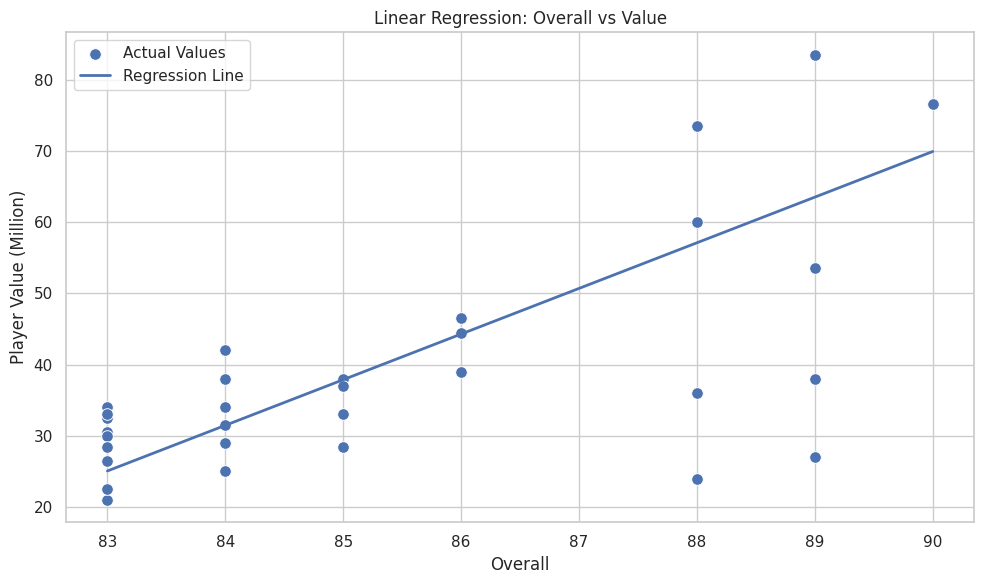

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_test["Overall"],
    y=y_test,
    s=70,
    label="Actual Values"
)

# Sort Overall values to draw the regression line correctly
order = np.argsort(X_test["Overall"].values)

plt.plot(
    X_test["Overall"].values[order],
    y_pred_simple[order],
    linewidth=2,
    label="Regression Line"
)

plt.title("Linear Regression: Overall vs Value")

plt.xlabel("Overall")

plt.ylabel("Player Value (Million)")

plt.legend()

plt.tight_layout()

plt.show()

## 7.2 الانحدار الخطي المتعدد

سنضيف `Age` إلى `Overall`.

هذا النموذج يسمح لنا باختبار ما إذا كان إدخال متغير إضافي يحسن القدرة التنبؤية مقارنة بالنموذج البسيط.

In [ ]:
# Create a Multiple Linear Regression model
multiple_model = LinearRegression()

# Train the model using Overall and Age as input features
multiple_model.fit(X_train, y_train)

# Predict player values using the test data
y_pred_multiple = multiple_model.predict(X_test)

# Calculate evaluation metrics for the model
multiple_metrics = {

    # Store the model name
    "Model": "Multiple Linear Regression",

    # Measure how much of the variation in Value_M is explained by the model
    "R2": r2_score(y_test, y_pred_multiple),

    # Calculate the average absolute prediction error
    "MAE": mean_absolute_error(y_test, y_pred_multiple),

    # Calculate the average squared prediction error
    "MSE": mean_squared_error(y_test, y_pred_multiple),

    # Calculate the square root of MSE using np.sqrt to avoid the deprecated 'squared' argument
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_multiple)),

}

# Convert the metrics into a DataFrame and display the results
display(pd.DataFrame([multiple_metrics]))

# Create a DataFrame containing each feature and its regression coefficient
coefficients = pd.DataFrame({

    # Store the feature names
    "Feature": features,

    # Store the coefficient assigned to each feature by the model
    "Coefficient": multiple_model.coef_

})

# Display the feature coefficients
display(coefficients)

,Model,R2,MAE,MSE,RMSE
0,Multiple Linear Regression,0.69,5.99,71.00,8.43


,Feature,Coefficient
0,Overall,7.65
1,Age,-2.98


## 7.3 Polynomial Regression

سنختبر درجات متعددة من Polynomial Regression باستخدام `Pipeline`.

**لماذا Pipeline؟**
لأنه يجمع خطوات التحويل والنموذج في كائن واحد، مما يقلل تكرار الأكواد ويجعل سير العمل أكثر وضوحًا.

سنقارن الدرجات من 1 إلى 5 باستخدام بيانات الاختبار، وليس بيانات التدريب.

In [ ]:
# Test polynomial degrees from 1 to 5
degrees = range(1, 6)

# Store the evaluation results for each degree
model_results = []

# Train and evaluate a separate model for each polynomial degree
for degree in degrees:

    # Create a pipeline that generates polynomial features
    # and then trains a linear regression model
    model = Pipeline([
        ("polynomial", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    # Train the model using the training data
    model.fit(X_train, y_train)

    # Predict player values using the test data
    predictions = model.predict(X_test)

    # Store the evaluation metrics for this degree
    model_results.append({
        "Degree": degree,

        # Measure how much of the variation is explained by the model
        "R2": r2_score(y_test, predictions),

        # Calculate the average absolute prediction error
        "MAE": mean_absolute_error(y_test, predictions),

        # Calculate the average squared prediction error
        "MSE": mean_squared_error(y_test, predictions),

        # Calculate the square root of MSE using np.sqrt to avoid the deprecated 'squared' argument
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
    })

# Convert all model results into a DataFrame
model_results_df = pd.DataFrame(model_results)

# Display the results for all polynomial degrees
display(model_results_df)

,Degree,R2,MAE,MSE,RMSE
0,1,0.69,5.99,71.00,8.43
1,2,0.83,4.54,40.29,6.35
2,3,0.84,4.36,36.82,6.07
3,4,0.85,4.44,35.54,5.96
4,5,0.82,4.93,40.50,6.36


## مقارنة أداء درجات Polynomial

سنرسم `R²` و`RMSE` عبر درجات النموذج.

- ارتفاع `R²` يعني أن النموذج يفسر نسبة أكبر من التباين في بيانات الاختبار.
- انخفاض `RMSE` يعني خطأ تنبؤيًا أقل.

لا ينبغي اختيار نموذج معقد لمجرد أن درجته أعلى؛ نستخدم أداء **بيانات الاختبار** للمقارنة.

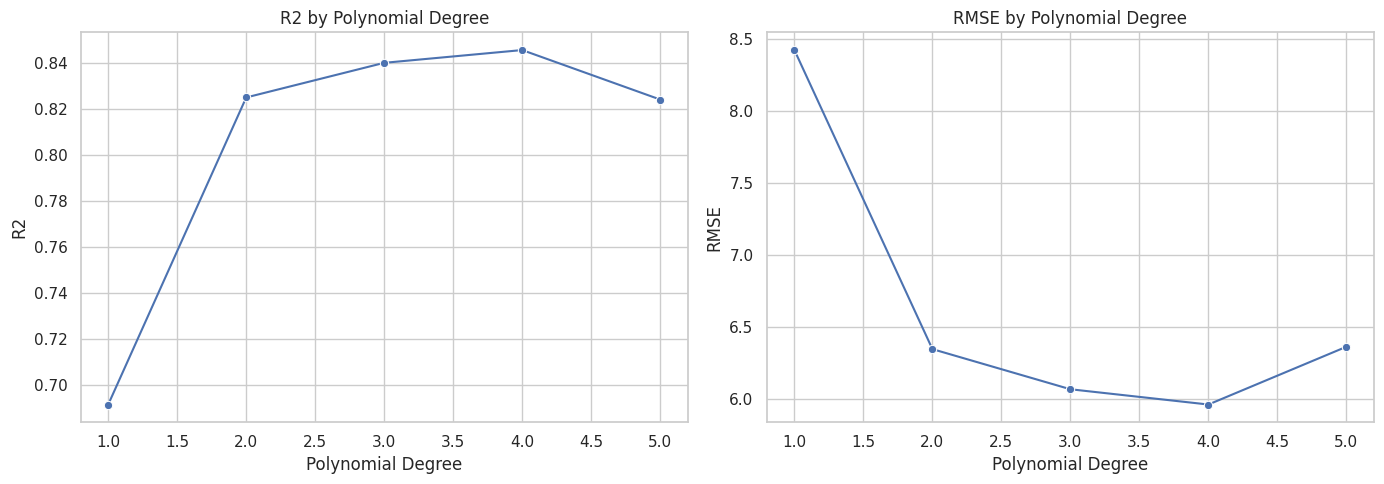

In [ ]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot R2 for each polynomial degree
sns.lineplot(
    data=model_results_df,
    x="Degree",
    y="R2",
    marker="o",
    ax=axes[0]
)

# Set the title and axis labels for the R2 plot
axes[0].set_title("R2 by Polynomial Degree")
axes[0].set_xlabel("Polynomial Degree")
axes[0].set_ylabel("R2")

# Plot RMSE for each polynomial degree
sns.lineplot(
    data=model_results_df,
    x="Degree",
    y="RMSE",
    marker="o",
    ax=axes[1]
)

# Set the title and axis labels for the RMSE plot
axes[1].set_title("RMSE by Polynomial Degree")
axes[1].set_xlabel("Polynomial Degree")
axes[1].set_ylabel("RMSE")

# Adjust the spacing between the plots
plt.tight_layout()

# Display the plots
plt.show()

# 8. فحص البواقي (Residual Analysis)

البواقي هي الفرق بين القيمة الحقيقية والقيمة المتوقعة:

$$Residual = Actual - Predicted$$

سنستخدمها لفحص ما إذا كان هناك نمط واضح لا يلتقطه النموذج الخطي.

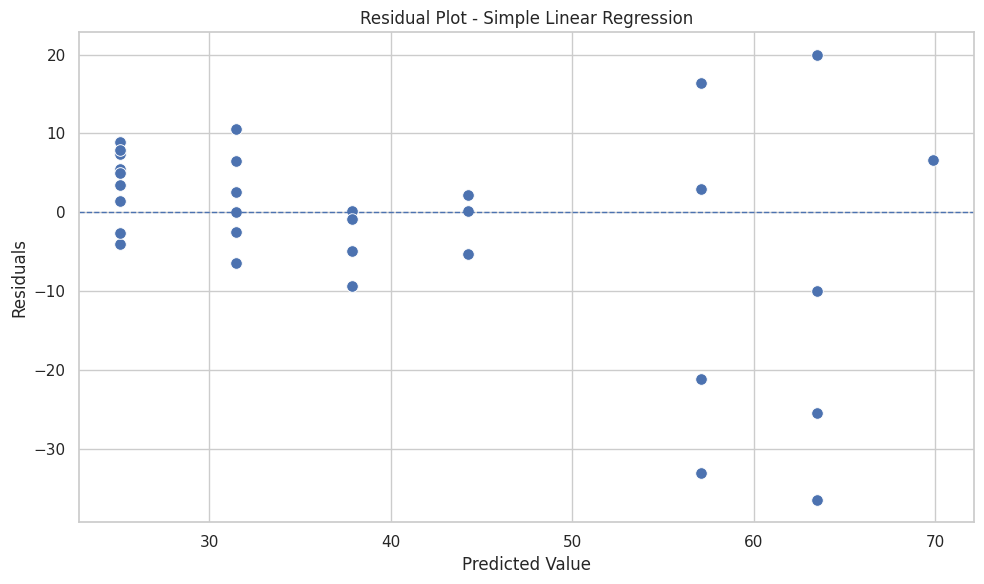

In [ ]:
# Calculate the residuals: actual values minus predicted values
residuals = y_test - y_pred_simple

# Create the residual plot
plt.figure(figsize=(10, 6))

# Plot predicted values against residuals
sns.scatterplot(
    x=y_pred_simple,
    y=residuals,
    s=70
)

# Add a horizontal reference line at zero
plt.axhline(0, linestyle="--", linewidth=1)

# Set the title and axis labels
plt.title("Residual Plot - Simple Linear Regression")
plt.xlabel("Predicted Value")
plt.ylabel("Residuals")

# Adjust the plot layout
plt.tight_layout()

# Display the plot
plt.show()

# 9. جدول ملخص للنماذج

سنضع النماذج الأساسية في جدول واحد لتسهيل قراءة النتائج.

**ملاحظة منهجية:** المقارنة هنا وصفية على مجموعة الاختبار المحددة بـ `random_state=42`، وليست حكمًا عامًا على جميع بيانات FIFA.

In [ ]:
baseline_results = pd.DataFrame([
    simple_metrics,
    multiple_metrics
])

display(baseline_results.sort_values("R2", ascending=False))

,Model,R2,MAE,MSE,RMSE
1,Multiple Linear Regression,0.69,5.99,71.00,8.43
0,Simple Linear Regression,0.31,8.71,158.29,12.58


# 10. الخلاصة والاستنتاجات (Conclusion & Insights)

## ما الذي أنجزناه؟

- قمنا بتحميل البيانات وفحص هيكلها.
- حسبنا القيم المفقودة بدل حذف الصفوف بلا دراسة.
- عالجنا القيم المفقودة بطريقة مختلفة حسب نوع المتغير.
- وحّدنا بعض أسماء الأندية.
- أنشأنا `Value_M` لتسهيل تفسير قيمة اللاعب.
- أجرينا تحليلًا وصفيًا ورسومًا بيانية للعمر والقيمة والأندية.
- فحصنا الارتباطات باستخدام Pearson وHeatmap.
- بنينا نماذج Linear وPolynomial Regression.
- استخدمنا Train/Test Split لتقييم النماذج على بيانات لم ترها أثناء التدريب.

## أهم الدروس المنهجية

1. **فهم البيانات يسبق النمذجة.**
2. **لا ينبغي حذف القيم المفقودة تلقائيًا.**
3. **الارتباط لا يساوي السببية.**
4. **تقييم النموذج على بيانات التدريب وحدها قد يعطي صورة مضللة عن الأداء.**
5. **التوثيق الجيد يجعل النوت بوك قابلة لإعادة الاستخدام والمراجعة.**


> **الخلاصة:** هذا المشروع يمثل دورة تحليل بيانات كاملة من الفحص والتنظيف إلى التصور والنمذجة، مع فصل واضح بين البيانات الخام والبيانات المعالجة وبين التدريب والاختبار.